In [4]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt 

In [5]:
df = pd.read_csv('Fashion_Retail_Sales_Cleaned_Transformed.csv')

In [6]:
df.columns

Index(['Order_ID', 'Order_Date', 'Order_Channel', 'Payment_Method',
       'Customer_ID', 'Customer_Name', 'Gender', 'Age', 'Age_Group',
       'Customer_Type', 'Segment', 'Product_Category', 'Product_Name', 'Brand',
       'Size', 'Color', 'Units_Sold', 'Unit_Price', 'Discount_%',
       'Sales_Amount', 'Cost_Amount', 'City', 'State', 'Region',
       'Return_Status', 'Order_Year', 'Order_Quarter', 'Profit',
       'Profit_Margin_%', 'Order_Month', 'Sales_Category', 'Profit_Category',
       'Customer_Order_Count', 'Product_Performance', 'Total_Units_Per_Order',
       'Order_Size'],
      dtype='object')

In [7]:
df.shape

(4000, 36)

In [8]:
total_sales =  df['Sales_Amount'].sum()
total_sales

12230418.600000001

### Total sales per customer: 

In [15]:
customer_sales = df.groupby('Customer_Name')['Sales_Amount'].sum()
customer_sales

Customer_Name
Aarav Agarwal     1469.30
Aarav Bhatt       2658.20
Aarav Chavan      6022.95
Aarav D'Souza     6685.55
Aarav Deshmukh     778.70
                   ...   
Yash Nair         3519.75
Yash Pawar        4857.20
Yash Rao          1079.10
Yash Verma         837.60
Yash Yadav        7440.15
Name: Sales_Amount, Length: 1350, dtype: float64

### Top 10 Customers

In [19]:
customer_sales_top10 = customer_sales.sort_values(ascending = False).head(10)
customer_sales_top10

Customer_Name
Vivek Chatterjee     336471.3
Kartik Jadhav        281360.8
Harsh Krishnan       204224.4
Aditya Reddy         200985.2
Siddharth Bhosale    187835.5
Akash Menon          174502.8
Meera Gupta          173361.5
Pallavi Verma        139297.1
Ritesh Mehta         134611.1
Trisha Reddy         125135.7
Name: Sales_Amount, dtype: float64

In [21]:
customer_sales_top20 = customer_sales.sort_values(ascending = False).head(20)
customer_sales_top20

Customer_Name
Vivek Chatterjee     336471.30
Kartik Jadhav        281360.80
Harsh Krishnan       204224.40
Aditya Reddy         200985.20
Siddharth Bhosale    187835.50
Akash Menon          174502.80
Meera Gupta          173361.50
Pallavi Verma        139297.10
Ritesh Mehta         134611.10
Trisha Reddy         125135.70
Ishaan Rao           122210.80
Bhavna Krishnan      121735.05
Akash Chatterjee     119752.00
Omkar Kulkarni       118243.25
Nandini Varma        113712.95
Ritika Joshi         112913.25
Priya Shinde         112427.85
Saurabh Shah         111678.60
Ritika Rao            98438.30
Lakshmi Gaikwad       92302.60
Name: Sales_Amount, dtype: float64

### Average Customer Spending 

In [24]:
customer_avg_spend = df.groupby(['Customer_ID','Customer_Name'])['Sales_Amount'].mean().sort_values(ascending = False)
customer_avg_spend

Customer_ID  Customer_Name    
CUST-0538    Ankit Fernandes      58703.250
CUST-0867    Chetan Shinde        46065.600
CUST-0901    Kartik Shetty        40724.600
CUST-1249    Kritika Khan         31029.300
CUST-1289    Kartik Banerjee      29305.450
                                    ...    
CUST-1308    Rahul Agarwal          339.150
CUST-1182    Chetan Chauhan         336.750
CUST-1278    Vaishnavi Gaikwad      279.300
CUST-1145    Rutuja Jadhav          273.025
CUST-0943    Lakshmi Sinha          261.750
Name: Sales_Amount, Length: 1350, dtype: float64

### Repeat Customer

In [27]:
repeat_customers = df.groupby(['Customer_ID','Customer_Name'])['Order_ID'].nunique().sort_values(ascending = False)        

In [29]:
four_repeat_customer = repeat_customers.head(4)
four_repeat_customer

Customer_ID  Customer_Name  
CUST-0580    Siddharth Patil    15
CUST-0190    Riya Pawar         15
CUST-0311    Kartik Jadhav      15
CUST-0205    Simran Pawar       15
Name: Order_ID, dtype: int64

In [31]:
customer_contribution = (customer_sales/total_sales)*100
print(f'{customer_contribution}')

Customer_Name
Aarav Agarwal     0.012013
Aarav Bhatt       0.021734
Aarav Chavan      0.049246
Aarav D'Souza     0.054663
Aarav Deshmukh    0.006367
                    ...   
Yash Nair         0.028779
Yash Pawar        0.039714
Yash Rao          0.008823
Yash Verma        0.006848
Yash Yadav        0.060833
Name: Sales_Amount, Length: 1350, dtype: float64


### Customer Segmentation

#### already done in data transformation

### Top 10 Customer

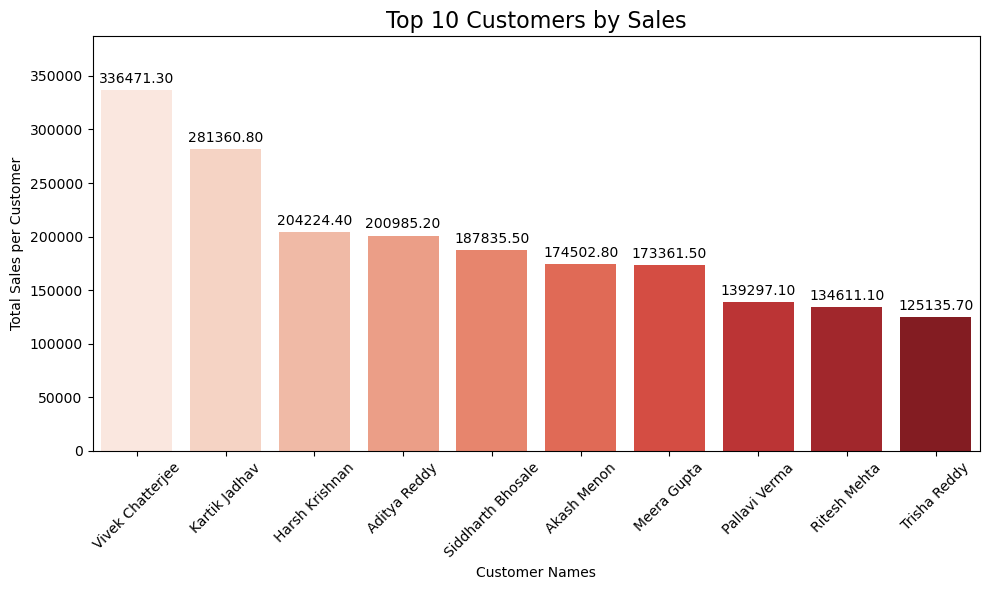

In [53]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=customer_sales_top10.index.astype(str),
    y=customer_sales_top10.values,
    hue=customer_sales_top10.index.astype(str),
    palette='Reds',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

ax.margins(y=0.15)

plt.title('Top 10 Customers by Sales', fontsize=16)
plt.xlabel('Customer Names')
plt.ylabel('Total Sales per Customer')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('Top 10 Customers by Sales.png', dpi = 600)
plt.show()

In [40]:
customer_type_sales = df.groupby('Customer_Type')['Sales_Amount'].sum()

In [46]:
customer_type_distribution = (customer_type_sales / total_sales)*100

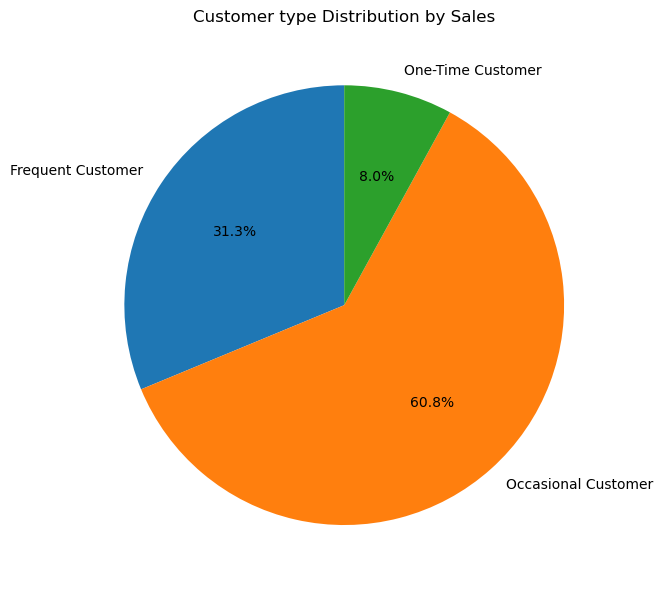

In [51]:
plt.figure(figsize = (10,6))
plt.pie(customer_type_distribution.values, 
        labels= customer_type_distribution.index, 
        autopct = '%1.1f%%', 
        startangle = 90)
plt.title('Customer type Distribution by Sales')

plt.tight_layout()
plt.savefig('Customer Segment Distribution by Sales.png', dpi = 600)
plt.show()


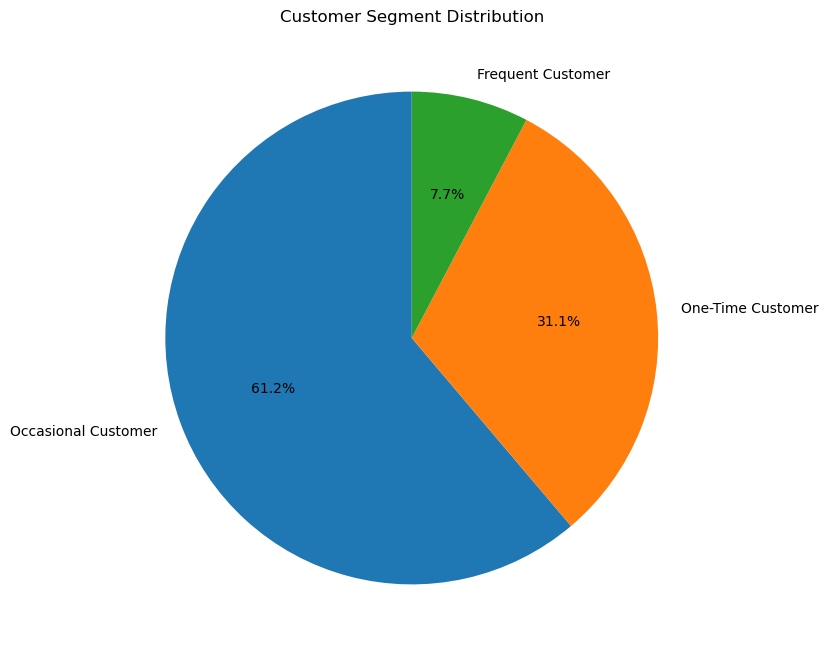

In [290]:
Customer_Segments = (
    df[['Customer_ID', 'Customer_Type']]
    .drop_duplicates('Customer_ID')
    ['Customer_Type']
    .value_counts()
)

plt.figure(figsize=(8, 8))

plt.pie(
    Customer_Segments.values,
    labels=Customer_Segments.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Segment Distribution')
plt.show()

In [292]:
Repeat_vs_OneTime = (
    df[['Customer_ID', 'Customer_Type']]
    .drop_duplicates('Customer_ID')
    ['Customer_Type']
    .replace({
        'Occasional Customer': 'Repeat Customer',
        'Frequent Customer': 'Repeat Customer'
    })
    .value_counts()
)

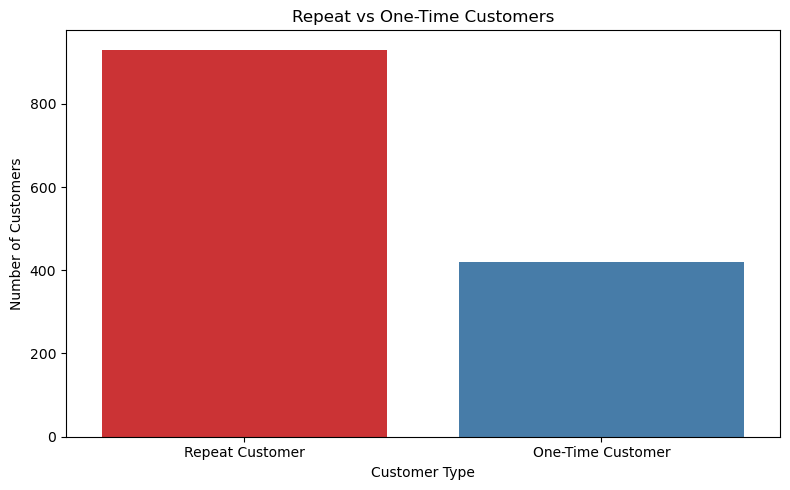

In [308]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=Repeat_vs_OneTime.index,
    y=Repeat_vs_OneTime.values,
    hue = Repeat_vs_OneTime.index,
    palette = 'Set1'
)

plt.title('Repeat vs One-Time Customers')
plt.xlabel('Customer Type')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()